In [1]:
import json
with open("../../outputs/hpo/phase_1/outputs.json", "r") as f:
    hpo_data = json.load(f)
with open("../../hpo/baseline_metrics.json", "r") as f:
    baseline_metrics = json.load(f)

In [2]:
trial_scores = {}
for trial in hpo_data.keys():
    trial_scores[trial] = {}

for dataset_name in ("nt_benchmark", "genomic_benchmark", "bend_benchmark", "chromatin_profile_prediction"):
    def get_tasks(trial):
        global dataset_name
        if dataset_name == "chromatin_profile_prediction":
            cpp = trial.get("chromatin_profile_prediction")
            if cpp is not None:
                return {"chromatin_profile_prediction": cpp}
            else:
                return None
        else:
            return trial.get(dataset_name)

    for trial in hpo_data.keys():
        tasks = get_tasks(hpo_data[trial])

        if tasks is not None:
            for name, val in tasks.items():
                if name == "pretraining": 
                    continue
                trial_scores[trial][name] = val[0][baseline_metrics[name]["metric"]]

In [3]:
# Cleanup
for trial_key in list(trial_scores.keys()):
    if len(trial_scores[trial_key]) != 30:
        del trial_scores[trial_key]

In [4]:
records_count = {t: 0 for t in trial_scores.keys()}
for task in trial_scores["1"].keys():
    best_score = 0
    best_trial = None
    for trial in trial_scores.keys():
        if trial_scores[trial][task] > best_score:
            best_score = trial_scores[trial][task]
            best_trial = trial

    records_count[best_trial] += 1

In [5]:
l = list(reversed(sorted(records_count.values())))
print(l)

[3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 0, 0, 0, 0, 0]


In [6]:
from copy import deepcopy
z_scores = deepcopy(trial_scores)

# Turn trial_scores into z_scores
for trial in trial_scores:
    for task in trial_scores[trial]:
        dataset_metrics = baseline_metrics[task]
        score = trial_scores[trial][task]
        score = (score - dataset_metrics["mean"]) / dataset_metrics["std"]
        z_scores[trial][task] = score

In [7]:
z_scores_on_records = {t: [0, [], 0] for t in trial_scores.keys()}

for task in z_scores["1"].keys():
    best_score = 0
    best_trial = None
    for trial in z_scores.keys():
        if z_scores[trial][task] > best_score:
            best_score = z_scores[trial][task]
            best_trial = trial

    old_mean = z_scores_on_records[best_trial][0]
    new_mean = old_mean + (best_score - old_mean) / (len(z_scores_on_records[best_trial][1]) + 1)
    z_scores_on_records[best_trial][0] = new_mean
    z_scores_on_records[best_trial][1].append(task)

KeyError: None

[-14.56452549344894, -1.6533857182584786, -13.371090076007189, -7.320468487519488, -6.254346496497696, -1.8909097398939114, -2.347023835495257, -13.824237328567524, -2.0044600290383507, -2.390330216788692, -13.775244228597714, -2.4634585416878823, -1.3579390078055078, -1.8257242771993, -13.573910349757712, -1.5855491100183559, -3.169627113570501, -2.628144968119658, -14.625846439320753, -13.795762648728672]


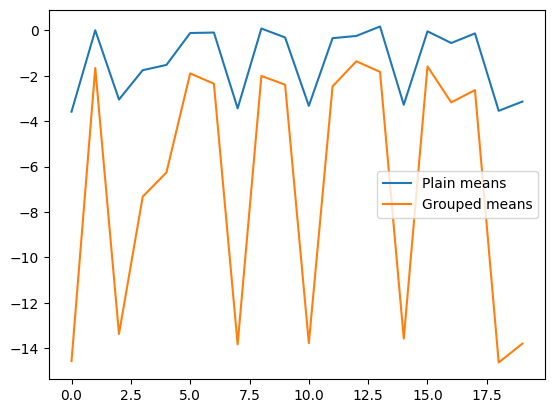

In [8]:
# Plot the grouped mean vs plain mean
from matplotlib import pyplot as plt

TASKS_GROUPS = {
    "histone": [
        "H2AFZ",
        "H3K27ac",
        "H3K27me3",
        "H3K36me3",
        "H3K4me1",
        "H3K4me2",
        "H3K4me3",
        "H3K9ac",
        "H3K9me3",
        "H4K20me1",
    ],
    "promoter": [
        "promoter_all",
        "promoter_tata",
        "promoter_no_tata",
        "human_nontata_promoters",
    ],
    "enhancers": [
        "enhancers",
        "enhancers_types",
        "dummy_mouse_enhancers_ensembl",
        "human_enhancers_cohn",
        "human_enhancers_ensembl",
        "human_ensembl_regulatory",
        "human_ocr_ensembl",
        "drosophila_enhancers_stark"
    ],
    "splicing": [
        "splice_sites_all",
        "splice_sites_donors",
        "splice_sites_acceptors",
    ],
    "general_genomic_content": [
        "demo_coding_vs_intergenomic_seqs",
        "demo_human_or_worm",
    ],
    "gene_finding": ["gene_finding"],
    "cpg_methylation": ["cpg_methylation"],
    "chromatin_profile_prediction": ["chromatin_profile_prediction"]
}

grouped_means = []
plain_means = []
for t in z_scores.keys():
    scores = z_scores[t]
    plain_means.append(sum(scores.values()) / len(scores))
    group_means = []
    for g in TASKS_GROUPS:
        s = 0
        for task in TASKS_GROUPS[g]:
            s += scores[task]
        group_means.append(s / len(TASKS_GROUPS[g]))
    group_mean = sum(group_means) / len(group_means)
    grouped_means.append(group_mean)
    z_scores_on_records[t][2] = group_mean

plt.plot(range(len(plain_means)), plain_means, label="Plain means")
plt.plot(range(len(grouped_means)), grouped_means, label="Grouped means")
plt.legend()

print(grouped_means)

In [9]:
from pprint import pprint
l = list(reversed(sorted(z_scores_on_records.values(), key=lambda x: x[2])))
pprint(l)

[[0.6439161944394669, ['human_ocr_ensembl'], -1.3579390078055078],
 [0, [], -1.5855491100183559],
 [2.6728160080072336,
  ['splice_sites_donors', 'splice_sites_acceptors', 'demo_human_or_worm'],
  -1.6533857182584786],
 [1.324162465348354, ['drosophila_enhancers_stark'], -1.8257242771993],
 [1.6517888095886555, ['H3K4me3', 'H3K27ac'], -1.8909097398939114],
 [1.8634231068195644,
  ['promoter_all', 'enhancers', 'human_enhancers_ensembl'],
  -2.0044600290383507],
 [1.565178411378843, ['splice_sites_all', 'H3K36me3'], -2.347023835495257],
 [0.8653026657783903, ['H3K4me1'], -2.390330216788692],
 [1.63427739258538, ['H2AFZ', 'H3K9ac'], -2.4634585416878823],
 [3.029662573655679, ['H4K20me1'], -2.628144968119658],
 [0, [], -3.169627113570501],
 [0.798808026230863, ['H3K4me2', 'enhancers_types'], -6.254346496497696],
 [1.502068892469928,
  ['H3K27me3', 'H3K9me3', 'human_enhancers_cohn'],
  -7.320468487519488],
 [3.3672652164350634,
  ['promoter_no_tata', 'cpg_methylation'],
  -13.37109007600718

In [2]:
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
)
import optuna

study = optuna.load_study(study_name="phase_1", storage="sqlite:///../../outputs/hpo/phase_1/optuna.db")
plot_optimization_history(study).show()
plot_param_importances(study).show()
print(study.best_params)

/home/pipev/miniconda3/envs/convnova/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'annotations_level': 1, 'include_cdjv_segments': 'true', 'include_pseudogenes': 'true', 'orient_all_segments': 'true', 'partial_canonicalization_works': 'false', 'transformation': 'rc'}


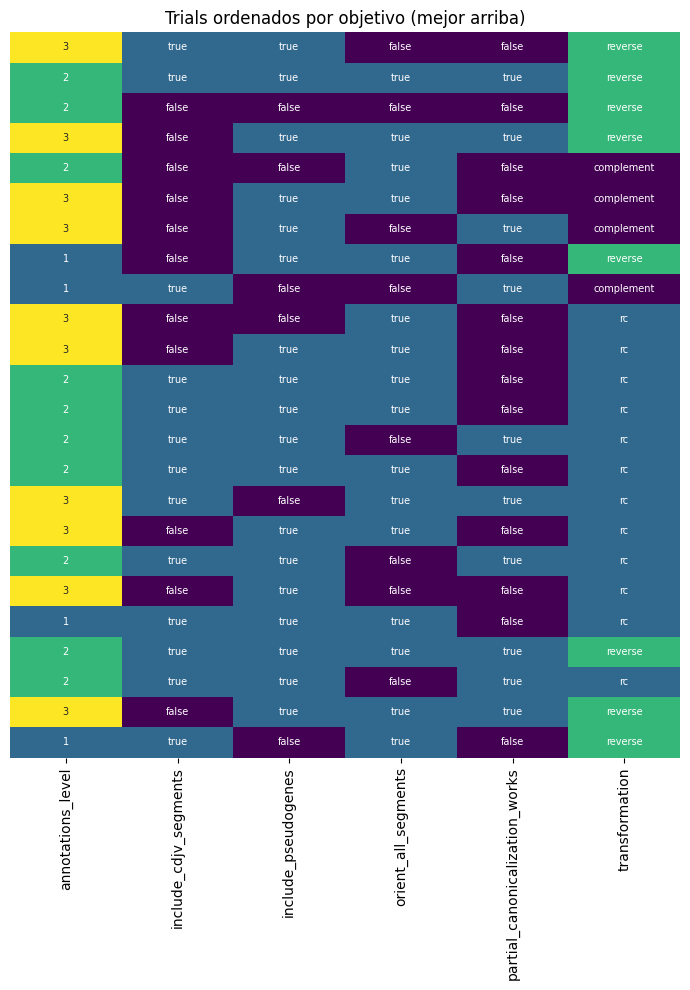

params_include_cdjv_segments: {'false': 0, 'true': 1}
params_include_pseudogenes: {'false': 0, 'true': 1}
params_orient_all_segments: {'false': 0, 'true': 1}
params_partial_canonicalization_works: {'false': 0, 'true': 1}
params_transformation: {'complement': 0, 'rc': 1, 'reverse': 2}


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = study.trials_dataframe()
param_cols = [c for c in df.columns if c.startswith("params_")]

df_sorted = df.sort_values("value", ascending=True)  # ajustar según minimizar/maximizar

# Detectar cuáles son categóricas (dtype object) vs binarias
cat_cols = [c for c in param_cols if df_sorted[c].dtype == object]
bin_cols = [c for c in param_cols if c not in cat_cols]

# Codificar categóricas a enteros, guardando el mapeo para la leyenda
encoded = df_sorted[param_cols].copy()
legends = {}
for c in cat_cols:
    cats = sorted(df_sorted[c].unique())
    mapping = {v: i for i, v in enumerate(cats)}
    encoded[c] = df_sorted[c].map(mapping)
    legends[c] = mapping

fig, ax = plt.subplots(figsize=(7, 10))
sns.heatmap(encoded, cmap="viridis", cbar=False, ax=ax,
            yticklabels=False, xticklabels=[c.replace("params_", "") for c in param_cols],
            annot=df_sorted[param_cols].values, fmt="", annot_kws={"size": 7})
ax.set_title("Trials ordenados por objetivo (mejor arriba)")
plt.tight_layout()
plt.show()

for c, m in legends.items():
    print(f"{c}: {m}")